# Estudio Comparativo para la Detección de Imágenes Sintéticas (IA vs Real)
## Fase I: Definición de la Línea Base (Baseline MLP)

### 1. Introducción y Contexto del Proyecto
El auge reciente de los modelos generativos profundos (especialmente los basados en arquitecturas de difusión como Stable Diffusion) ha transformado la visión por computador, permitiendo generar imágenes sintéticas con un realismo visual sin precedentes. La diferenciación automática entre contenido fotográfico real e imágenes generadas por IA representa un reto crítico contra la desinformación y la autenticación digital.

En el marco de la asignatura *Procesamiento de Imágenes Digitales*, este trabajo no busca aplicar directamente la técnica más compleja desde el inicio, sino desarrollar un **estudio comparativo experimental** estructurado en tres metodologías progresivas:
1. **Tier 1 (Línea Base):** Aplanamiento de la imagen en un vector unidimensional y clasificación mediante una Red Neuronal Densa (Perceptrón Multicapa / MLP).
2. **Tier 2 (PID Tradicional):** Extracción matemática manual de características de contorno y textura mediante descriptores HOG y LBP combinados con un clasificador SVM.
3. **Tier 3 (Deep Learning Espacial):** Extracción automática de características mediante una Red Neuronal Convolucional (CNN).

El objetivo final consiste en evaluar cuantitativamente el **equilibrio (*trade-off*) entre el rendimiento predictivo (Accuracy, F1-Score) y el coste computacional (tiempo de cómputo y latencia de inferencia)** a medida que incrementamos el nivel de abstracción de los datos.

---

### 2. Descripción Técnica del Dataset CIFAKE
Para este estudio se utiliza el dataset de referencia **CIFAKE** (publicado en Kaggle por Jordan J. Bird), fundamentado en la base de datos CIFAR-10 y generadores de difusión:
- **Volumen total:** 120.000 imágenes RGB en color con una resolución estandarizada de $32 \times 32$ píxeles.
- **División de datos:** 100.000 imágenes para entrenamiento (*train set*) y 20.000 imágenes para evaluación (*test set*).
- **Balanceo estricto de clases:** Proporción simétrica del 50% de imágenes reales (extraídas de CIFAR-10) y 50% de imágenes sintéticas generadas específicamente con el modelo **Stable Diffusion v1.4**.
- **Categorías semánticas:** Distribución homogénea a lo largo de 10 clases balanceadas (aviones, coches, pájaros, gatos, ciervos, perros, ranas, caballos, barcos y camiones), lo que elimina sesgos de clase y permite evaluar la respuesta ante morfologías visuales heterogéneas.

---

### 3. Consideraciones Computacionales y Restricciones de Hardware
Uno de los pilares metodológicos de este trabajo es la reproducibilidad y la viabilidad técnica en entornos de computación convencionales.Por ejemplo los experimentos de este notebook se ejecutan en un **ordenador portátil estándar equipado con un procesador Intel Core i5 comercial y sin aceleración por GPU dedicada**.

Esta restricción de hardware plantea retos técnicos y decisiones de diseño concretas:
1. **Gestión de memoria y flujo de datos:** Aunque el volumen de datos en disco es relativamente ligero (~150-200 MB descomprimidos debido a la resolución de $32 \times 32$ píxeles), gestionar 120.000 archivos individuales puede saturar el sistema operativo. Se implementa un pipeline mediante `DataLoader` que suministra imágenes en pequeños lotes (*batches*) de 64 muestras, manteniendo el consumo de memoria RAM por debajo de 1.5 GB.
2. **Estabilidad en entorno Windows:** Se establece `num_workers = 0` en la carga de datos para ejecutar los procesos en el hilo principal de la CPU, evitando bloqueos por multiprocesamiento o conflictos en la gestión de subprocesos locales.
3. **Optimización aritmética:** La CPU aprovecha las instrucciones vectoriales modernas (AVX) para ejecutar las operaciones de álgebra lineal requeridas por las capas densas, logrando tiempos de entrenamiento sostenibles (~3-4 minutos por época) y una latencia de inferencia mínima (< 0.1 ms por imagen).

---
### 4. Descripción y Justificación del Ecosistema de Librerías

Para la implementación del flujo de trabajo, se emplean librerías especializadas del ecosistema científico de Python, seleccionadas por su robustez, optimización aritmética y compatibilidad:

- **`torch` (PyTorch):** Núcleo fundamental del proyecto. Es el framework de aprendizaje profundo que proporciona estructuras de datos basadas en tensores multidimensionales con aceleración aritmética vectorial. Gestiona de manera automática el motor de diferenciación matemática (*Autograd*) para calcular las derivadas y gradientes durante la retropropagación (*backpropagation*).
- **`torch.nn`:** Submódulo que encapsula las piezas estructurales de las arquitecturas neuronales. Proporciona capas ya optimizadas (como `nn.Linear` para transformaciones afines completamente conectadas, `nn.Flatten` para la serialización 1D y `nn.Dropout` para regularización), además de funciones de coste estandarizadas como `nn.CrossEntropyLoss`.
- **`torch.optim`:** Módulo que implementa algoritmos de optimización numérica basados en el descenso de gradiente estocástico. Se utiliza el optimizador `Adam` para actualizar dinámicamente los pesos en cada iteración mediante estimaciones adaptativas de los momentos de los gradientes.
- **`torchvision.datasets` y `torchvision.transforms`:** Herramientas de visión artificial específicas para PyTorch. `datasets.ImageFolder` automatiza la lectura y el etiquetado a partir de la estructura de carpetas de CIFAKE, mientras que `transforms` permite definir la cadena de preprocesamiento (conversión de píxeles a punto flotante con `ToTensor` y su estandarización estadística con `Normalize`).
- **`torch.utils.data.DataLoader`:** Componente encargado de gestionar la eficiencia de la memoria RAM. Implementa generadores que extraen las muestras en minilotes (*mini-batches*), barajan los datos aleatoriamente en cada época (*shuffling*) y controlan el flujo de datos hacia la CPU sin necesidad de saturar la memoria con el dataset completo.
- **`sklearn.metrics` (Scikit-Learn):** Módulo estándar en ciencia de datos utilizado en la fase final de validación cuantitativa. Permite extraer de forma desacoplada del framework de deep learning métricas rigurosas (Precision, Recall, F1-Score general y por clase mediante `classification_report`) y calcular la `confusion_matrix` para evaluar desbalances en las clasificaciones erróneas.

### 5. Objetivo Específico de este Notebook (Tier 1)
El propósito exclusivo de este notebook es formalizar la **cota inferior de rendimiento (*baseline*)**. Al forzar el aplanamiento de la matriz tridimensional ($32 \times 32 \times 3$) a un vector de 3072 valores, se destruye deliberadamente la topología 2D y la matriz de adyacencia entre píxeles vecinos. 

El resultado obtenido servirá como punto de referencia mínimo para contrastar si la inclusión posterior de descriptores clásicos de procesamiento de imágenes (HOG y LBP) y capas convolucionales justifica su sobrecoste de cálculo frente a este clasificador elemental.

# Fase 1: Baseline - Detección de Imágenes Sintéticas (CIFAKE)
## 1. Configuración del Entorno y Reproducibilidad

En este primer bloque se define el dispositivo de cómputo (CPU) y se establece una semilla (*seed*) global fija. Esto asegura la reproducibilidad experimental de las pruebas y la inicialización de los pesos de la red.

In [1]:
import os
import random
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Configuración del dispositivo (CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo seleccionado: {device}")

# 2. Control de reproducibilidad
SEED = 42

def set_seed(seed_value):
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)

set_seed(SEED)
print(f"Semilla global establecida en: {SEED}")

Dispositivo seleccionado: cpu
Semilla global establecida en: 42


## 2. Pipeline de Preprocesamiento y Carga del Dataset

Cargamos las imágenes normalizándolas al intervalo [-1, 1] y convirtiéndolas en tensores de PyTorch. Se utiliza `DataLoader` para cargar los datos en lotes (*batches*) de 64 muestras, optimizando el uso de la memoria RAM.

In [2]:
# Ruta del dataset (ajustar según la carpeta local)
DATASET_PATH = "archive"

# Transformaciones: escalado a [0, 1] y normalización a [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

# Carga de carpetas Train y Test
train_dataset = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "train"), transform=transform)
test_dataset  = datasets.ImageFolder(root=os.path.join(DATASET_PATH, "test"),  transform=transform)

print(f"Mapeo de etiquetas: {train_dataset.class_to_idx}")
print(f"Muestras de entrenamiento: {len(train_dataset)} | Muestras de prueba: {len(test_dataset)}")

# DataLoaders con num_workers=0 para estabilidad en CPU/Windows
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False, num_workers=0)

Mapeo de etiquetas: {'FAKE': 0, 'REAL': 1}
Muestras de entrenamiento: 100000 | Muestras de prueba: 20000


## 3. Arquitectura del Modelo: Perceptrón Multicapa (MLP)

En este modelo de referencia (*baseline*), la imagen 2D (32x32x3) se aplana directamente mediante `nn.Flatten` en un vector unidimensional de 3072 valores. Este proceso destruye deliberadamente las relaciones espaciales locales para evaluar el rendimiento mínimo de una red densa.

In [3]:
class BaselineMLP(nn.Module):
    def __init__(self):
        super(BaselineMLP, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Linear(32 * 32 * 3, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 2)  # Salida binaria: FAKE (0) o REAL (1)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.classifier(x)

model = BaselineMLP().to(device)
print(model)

BaselineMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=2, bias=True)
  )
)


## 4. Entrenamiento del Modelo

Se utiliza la función de pérdida `CrossEntropyLoss` y el optimizador `Adam` con una tasa de aprendizaje de 0.001. Se cronometra el tiempo total de entrenamiento sobre 5 épocas completas.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 5
start_total_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    start_epoch_time = time.time()
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        # 1. Reiniciar gradientes
        optimizer.zero_grad()
        # 2. Paso hacia adelante
        outputs = model(images)
        # 3. Calcular pérdida
        loss = criterion(outputs, labels)
        # 4. Retropropagación y actualización
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
    epoch_time = time.time() - start_epoch_time
    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    
    print(f"Época {epoch+1:02d}/{EPOCHS:02d} | Tiempo: {epoch_time:.1f}s | Pérdida: {epoch_loss:.4f} | Precisión: {epoch_acc:.2f}%")

total_time = time.time() - start_total_time
print(f"\nTiempo total de entrenamiento: {total_time:.2f} segundos")

Época 01/05 | Tiempo: 245.5s | Pérdida: 0.4970 | Precisión: 75.16%
Época 02/05 | Tiempo: 203.3s | Pérdida: 0.4390 | Precisión: 79.24%
Época 03/05 | Tiempo: 127.0s | Pérdida: 0.4083 | Precisión: 81.00%
Época 04/05 | Tiempo: 191.9s | Pérdida: 0.3834 | Precisión: 82.31%
Época 05/05 | Tiempo: 206.4s | Pérdida: 0.3639 | Precisión: 83.58%

Tiempo total de entrenamiento: 974.12 segundos


## 5. Evaluación en Conjunto de Prueba y Exportación

Se desactiva el cálculo de gradientes (`torch.no_grad()`) para evaluar el rendimiento sobre las 20.000 imágenes de prueba, calculando la latencia media de inferencia, el informe de métricas y la matriz de confusión. Finalmente, se guardan los pesos en disco.

Evaluando en el conjunto de prueba...

Latencia media de inferencia: 0.0787 ms por imagen

--- INFORME DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

        FAKE     0.8290    0.8016    0.8151     10000
        REAL     0.8080    0.8347    0.8211     10000

    accuracy                         0.8182     20000
   macro avg     0.8185    0.8181    0.8181     20000
weighted avg     0.8185    0.8182    0.8181     20000



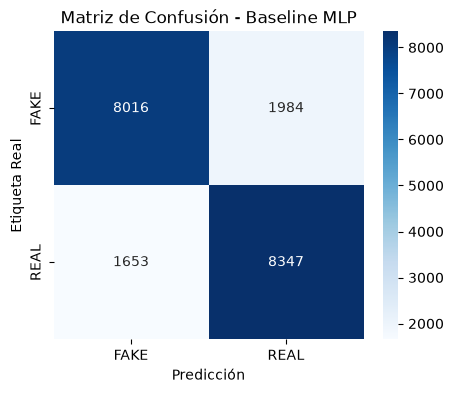

Pesos del modelo guardados correctamente en 'baseline_mlp.pth'


In [6]:
model.eval()
all_preds = []
all_labels = []
inference_times = []

print("Evaluando en el conjunto de prueba...")

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        
        # Medida de latencia por lote
        t0 = time.time()
        outputs = model(images)
        t1 = time.time()
        
        batch_size_curr = images.size(0)
        inference_times.append((t1 - t0) / batch_size_curr)
        
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 1. Latencia media de inferencia
avg_latency_ms = np.mean(inference_times) * 1000
print(f"\nLatencia media de inferencia: {avg_latency_ms:.4f} ms por imagen")

# 2. Reporte de clasificación
class_names = list(train_dataset.class_to_idx.keys())
print("\n--- INFORME DE CLASIFICACIÓN ---")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 3. Matriz de Confusión
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicción')
plt.ylabel('Etiqueta Real')
plt.title('Matriz de Confusión - Baseline MLP')
plt.show()

# 4. Guardar el modelo entrenado en disco
torch.save(model.state_dict(), "baseline_mlp3.pth")
print("Pesos del modelo guardados correctamente en 'baseline_mlp.pth'")